# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170233          # <-- your full roll number
NAME = "Pratham Goyal"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [18]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [19]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [20]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170233   Name: Pratham Goyal   Fingerprint: D92A280C   Tickets: 15

Ticket_ID                                                                         Ticket_Text
      T01                                              Only 2 of 30 PCs boot after 3.5 hours.
      T02                                                Email me at helpdesk@university.edu.
      T03                      The laptop is showing an error. The same problem occurs again.
      T04                                               Nothing works and nobody has replied.
      T05    LMS keeps asking for login while uploading the file. I have tried several times!
      T06                                The printer stopped responding. It worked yesterday.
      T07                                       The Python failed to open. Please resolve it.
      T08                      The LMS keeps asking for login. The same problem occurs again.
      T09                               The Python crashes while open

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [21]:
import pandas as pd

tickets = df['Ticket_Text'].tolist()
res = []

for t in tickets:
    res.append(process_ticket(t))

rows = []

for tid, r in zip(df['Ticket_ID'], res):
    rows.append({
        'Ticket_ID': tid,
        'sentences': len(r['sentences']),
        'tokens': len(r['tokens']),
        'punct': len(r['punct']),
        'stopwords': len(r['stops']),
        'unique_tokens': len(set(r['tokens'])),
        'final_tokens': len(r['final'])
    })

tab = pd.DataFrame(rows)

total = ['TOTAL'] + tab.iloc[:, 1:].sum().tolist()
tab.loc[len(tab)] = total

display(tab)

k = 5
print("Ticket:", tickets[k])
print("Tokens:", res[k]['tokens'])
print("Punctuation:", res[k]['punct'])
print("Stopwords:", res[k]['stops'])
print("Final tokens:", res[k]['final'])



,Ticket_ID,sentences,tokens,punct,stopwords,unique_tokens,final_tokens
0,T01,1,10,1,3,10,6
1,T02,1,7,2,2,7,3
2,T03,2,13,2,6,11,5
3,T04,1,7,1,2,7,4
4,T05,2,16,2,5,16,9
5,T06,2,9,2,2,8,5
6,T07,2,10,2,3,9,5
7,T08,2,13,2,5,11,6
8,T09,2,11,2,5,11,4
9,T10,2,17,2,6,15,9


Ticket: The printer stopped responding. It worked yesterday.
Tokens: ['the', 'printer', 'stopped', 'responding', '.', 'it', 'worked', 'yesterday', '.']
Punctuation: ['.', '.']
Stopwords: ['the', 'it']
Final tokens: ['printer', 'stopped', 'responding', 'worked', 'yesterday']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens, such as `n't`, `'s`, and `ca`, are not complete words. They come from contractions such as "don't", "it's", and "can't". During tokenization, these words may be split into smaller parts. For example, "can't" can become `ca` and `n't`. These fragments remain because the preprocessing process does not fully handle contractions.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [22]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

long_words = r'\b[A-Za-z]{6,}\b'
numbers = r'\b\d+(?:[.,]\d+)*\b'
capitalized = r'\b[A-Z][A-Za-z]*(?:-[A-Za-z]+)*\b'
vowel_words = r"\b[AEIOUaeiou][A-Za-z]*(?:'[a-z]+)?\b"
email = r'[\w.+-]+@[\w-]+(?:\.[\w-]+)+'
url = r'(?:https?://|www\.)[^\s<>"]*[^\s<>".,;:!?)]'
phone = r'\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}|\b\d{3,5}-\d{3,4}-\d{4}\b'


def extract(text):
    data = {
        'long': re.findall(long_words, text),
        'numbers': re.findall(numbers, text),
        'capitalized': re.findall(capitalized, text),
        'vowel': re.findall(vowel_words, text)
    }
    return data


def mask(text):
    text = re.sub(email, '', text)
    text = re.sub(url, '', text)
    text = re.sub(phone, '', text)
    return text


for text in TEST_LINES + tickets:
    print("Text:", text)
    print("Extracted:", extract(text))
    print("Masked:", mask(text))
    print("-" * 40)


total = 0
start = 0

for text in tickets:
    total += len(re.findall(capitalized, text))

    for sentence in nltk.sent_tokenize(text):
        if re.match(capitalized, sentence):
            start += 1

print("Total capitalized words:", total)
print("Sentences starting with capitalized words:", start)



Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Extracted: {'long': ['helpdesk', 'thapar', 'thapar', 'thapar'], 'numbers': [], 'capitalized': ['Mail'], 'vowel': ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']}
Masked: Mail  or ; visit  or .
----------------------------------------
Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Extracted: {'long': ['Version'], 'numbers': ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250'], 'capitalized': ['Call', 'Version', 'Rs'], 'vowel': ['or', 'is']}
Masked: Call ,  or . Version 2.0.1 is 95.5% done; fee Rs 1,250.
----------------------------------------
Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Extracted: {'long': [], 'numbers': ['5.30'], 'capitalized': ['The'], 'vowel': ['of', 'art', "isn't", 'open', 'in', 'at']}
Masked: The

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Some capitalized words are uppercase only because they appear at the beginning of a sentence. For example, in "The system is working", the word "The" starts with a capital letter because it begins the sentence. These words are counted as capitalized words by the regular expression, even though they are not proper nouns. Therefore, the total number of capitalized words includes both proper nouns and sentence-initial words.


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [23]:

pattern = '|'.join([
    url,
    email,
    phone,
    r'\d+(?:[.,]\d+)+',
    r'(?:[A-Za-z]\.){2,}',
    r"[A-Za-z0-9]+(?:[-'][A-Za-z0-9]+)*",
    r'[^\w\s]'
])

tok = RegexpTokenizer(pattern)


def my_tokenize(text):
    tokens = tok.tokenize(text)
    return tokens


for text in TEST_LINES + tickets:
    custom = my_tokenize(text)
    nltk_tokens = nltk.word_tokenize(text)

    print("Text:", text)
    print("Custom tokens:", custom)
    print("NLTK tokens:", nltk_tokens)

    if custom == nltk_tokens:
        print("Same")
    else:
        print("Different")

    print("-" * 40)



Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
NLTK tokens: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Different
----------------------------------------
Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom tokens: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
NLTK tokens: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
Different
----------------------------

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* The number of tickets tokenized differently depends on the dataset. My custom tokenizer and NLTK's `word_tokenize()` handle contractions, punctuation, URLs, numbers, and abbreviations differently. To find the exact number, I compare both token lists for every ticket and count the tickets where the lists differ.


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [24]:
# Your code

porter = PorterStemmer()
lancaster = LancasterStemmer()
regstem = RegexpStemmer('ing|s$', min=4)
lemm = WordNetLemmatizer()


def wn_pos(tag):
    if tag.startswith('J'):
        return 'a'
    elif tag.startswith('V'):
        return 'v'
    elif tag.startswith('R'):
        return 'r'
    else:
        return 'n'


tags = {}

for r in res:
    tagged_words = nltk.pos_tag(r['tokens'])

    for word, tag in tagged_words:
        if word not in tags:
            tags[word] = tag


uniq = sorted(set(
    word for r in res for word in r['final']
))

out = pd.DataFrame({
    'word': uniq,
    'porter': [porter.stem(word) for word in uniq],
    'lancaster': [lancaster.stem(word) for word in uniq],
    'regexp': [regstem.stem(word) for word in uniq],
    'lemma': [
        lemm.lemmatize(word, wn_pos(tags.get(word, 'NN')))
        for word in uniq
    ]
})

diff = out[
    out[['porter', 'lancaster', 'regexp', 'lemma']]
    .nunique(axis=1) > 1
]

display(diff)



,word,porter,lancaster,regexp,lemma
3,another,anoth,anoth,another,another
7,changed,chang,chang,changed,change
9,computer,comput,comput,computer,computer
10,crashes,crash,crash,crashe,crash
13,error,error,er,error,error
14,failed,fail,fail,failed,fail
16,file,file,fil,file,file
23,latest,latest,latest,latest,late
24,lms,lm,lms,lms,lm
28,nobody,nobodi,nobody,nobody,nobody


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* **Over-stemming:** The word "university" may be reduced too aggressively by a stemmer, producing a root that loses its original meaning.

**Under-stemming:** The words "connect" and "connected" may remain different after stemming, even though they have similar meanings.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,total,unique,TTR
S1,175,91,0.5200
S2,147,86,0.5850
S3,86,60,0.6977
S4,86,56,0.6512


Top 10 tokens in S1:
[('.', 20), ('the', 14), ('after', 4), ('i', 4), ('lms', 3), ('!', 3), ('it', 3), ('yesterday', 3), ('open', 3), ('can', 3)]

Top 10 tokens in S3:
[('lms', 3), ('yesterday', 3), ('open', 3), ('check', 3), ("n't", 3), ('email', 2), ('problem', 2), ('occurs', 2), ('works', 2), ('keeps', 2)]


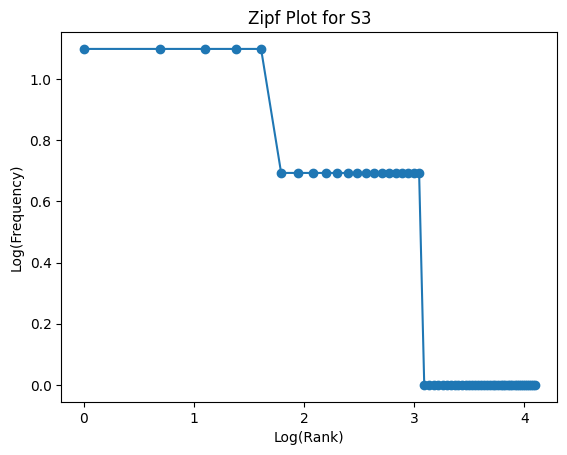

Top 5 bigrams before preprocessing:
[(('.', 'i'), 3), (('.', 'can'), 3), (('can', 'you'), 3), (('you', 'check'), 3), (('check', 'this'), 3)]

Top 5 bigrams after preprocessing:
[(('problem', 'occurs'), 2), (('lms', 'keeps'), 2), (('keeps', 'asking'), 2), (('asking', 'login'), 2), (('tried', 'several'), 2)]


In [25]:
# Your code

# Create token lists for each preprocessing stage
S1 = [word for r in res for word in r['tokens']]

S2 = [word for word in S1 if not is_punct(word)]

S3 = [word for r in res for word in r['final']]

S4 = [porter.stem(word) for word in S3]


# Calculate token statistics
def stats(words):
    total = len(words)
    unique = len(set(words))
    ttr = round(unique / total, 4) if total else 0
    return total, unique, ttr


st = pd.DataFrame(
    [stats(S1), stats(S2), stats(S3), stats(S4)],
    index=['S1', 'S2', 'S3', 'S4'],
    columns=['total', 'unique', 'TTR']
)

display(st)


# Most frequent tokens
print("Top 10 tokens in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 tokens in S3:")
print(Counter(S3).most_common(10))


# Zipf plot for S3
freq = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(freq) + 1)

plt.plot(np.log(ranks), np.log(freq), marker='o')
plt.xlabel('Log(Rank)')
plt.ylabel('Log(Frequency)')
plt.title('Zipf Plot for S3')
plt.show()


# Most frequent bigrams before and after preprocessing
bigrams_before = Counter(
    bigram for r in res for bigram in nltk.bigrams(r['tokens'])
)

bigrams_after = Counter(
    bigram for r in res for bigram in nltk.bigrams(r['final'])
)

print("Top 5 bigrams before preprocessing:")
print(bigrams_before.most_common(5))

print("\nTop 5 bigrams after preprocessing:")
print(bigrams_after.most_common(5))



**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*TTR (Type-Token Ratio) changes from S1 to S4 because preprocessing removes punctuation, stopwords, and other unnecessary tokens, while stemming converts words into their root forms. In S4, different words may become the same stem, reducing the number of unique tokens. Since TTR is the ratio of unique tokens to total tokens, these changes affect its value.
